# Applied Machine Learning — Assignment 2 (ML Workflow)

Predicting **Fitness Level** (High / Low) from the fitness dataset.

## Narrative
EDA showed class imbalance (~75/25), heavy missingness in Activity Index, and clear lifestyle signals (Activity, Nutrition, Smoker). This notebook:

1. Applies the **same quality rules** as the EDA notebook  
2. Trains **seven** models with one shared pipeline  
3. **Tunes each model** (fair comparison)  
4. Selects the winner by **CV macro-F1** and analyses errors  

**Selection rule:** best mean 5-fold CV macro-F1 after tuning (not raw accuracy, not a single test peek).


---
## Task 2.1 — Design & justification

### Data processing (handoff from EDA)
- **Drop** ghost rows (≥80% NaN) and exact duplicates — no usable / redundant rows.
- **Blood Pressure == 0 → NaN** — impossible systolic; then median-impute in the pipeline.
- **Clip Weight** to [35, 161] — implausible lows and extreme highs.
- Keep HR>100 and Sleep>9.5 — unusual but plausible (documented in EDA).
- Features kept: BMI, Age, Activity Index, Sleep Hours, Nutrition Quality, Blood Pressure, Gender, Smoker.
- Dropped: Height & Weight (folded into BMI), Heart Rate (weak separation in EDA).
- **Median imputation** for all numerics + StandardScaler — one robust rule for skewed health data with recording gaps. Fit inside the pipeline (train folds only).

### Models (seven — equal opportunity)
| Model | Role |
|-------|------|
| Logistic Regression | Interpretable linear baseline |
| Random Forest | Non-linear ensemble |
| Hist Gradient Boosting | Strong tabular booster (sklearn) |
| KNN | Distance-based (needs scaling — we scale) |
| Naive Bayes | Simple / robust on noisy small data |
| SVM (RBF) | Non-linear margin classifier |
| MLP | Simple neural net (1–2 hidden layers) |

### Class imbalance
- Always-Low ≈ 75% accuracy with **0** High recall.
- **SMOTE inside** `ImbPipeline` (training folds only) — keep all Low rows; do not also use `class_weight`.
- Optimise / rank with **macro F1**.

### Validation & tuning
- Stratified 80/20 hold-out + **5-fold StratifiedKFold**
- **RandomizedSearchCV** on every model (`f1_macro`) so comparison is fair
- Learning curve + confusion matrix for the **winner only**


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, learning_curve,
)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
N_ITER = 12
np.random.seed(SEED)
print("Imports OK")


Imports OK


---
## Task 2.2 — Implementation

### Step 1: Load, clean, engineer features

*Colab: upload `fitness_dataset.csv` to the working directory first.*


In [2]:
df = pd.read_csv("fitness_dataset.csv")
print(f"Raw shape: {df.shape}")

# 1) Ghost rows + duplicates (show duplicates, then drop) — same as EDA
thresh = int(0.8 * len(df.columns))
ghost = df[df.isnull().sum(axis=1) >= thresh]
n_dup = int(df.duplicated().sum())
print(f"Ghost rows: {len(ghost)}; exact duplicates: {n_dup}")
if n_dup > 0:
    print("Duplicate row(s):")
    print(df[df.duplicated(keep=False)].to_string())
df = df.drop(index=ghost.index).drop_duplicates().reset_index(drop=True)

# 2) Blood Pressure == 0 → NaN (impossible systolic)
n_bp0 = int((df["Blood Pressure"] == 0).sum())
df.loc[df["Blood Pressure"] == 0, "Blood Pressure"] = np.nan
print(f"Blood Pressure == 0 → NaN: {n_bp0} rows; BP min now {df['Blood Pressure'].min():.1f}")

# 3) Weight clip [35, 161]
n_low = int((df["Weight"] < 35).sum())
n_high = int((df["Weight"] > 161).sum())
df["Weight"] = df["Weight"].clip(lower=35, upper=161)
print(f"Weight clipped (<35: {n_low}, >161: {n_high})")
print(f"After clean: {df.shape}")

# 4) BMI + encode
df["BMI"] = df["Weight"] / ((df["Height"] / 100) ** 2)
df["Gender_enc"] = (df["Gender"].fillna("Female") == "Male").astype(int)
df["Smoker_enc"] = (df["Smoker"].fillna("No") == "Yes").astype(int)
df["Target"] = (df["Fitness Level"] == "High").astype(int)

NUMERIC = ["BMI", "Age", "Activity Index", "Sleep Hours",
           "Nutrition Quality", "Blood Pressure"]
BINARY = ["Gender_enc", "Smoker_enc"]

X = df[NUMERIC + BINARY].copy()
y = df["Target"].copy()

print("Class balance:")
print(y.value_counts(normalize=True).round(3))
print("Features:", list(X.columns))


Raw shape: (1610, 11)
Ghost rows: 11; exact duplicates: 1
Duplicate row(s):
     Height  Age Gender Smoker  Activity Index  Sleep Hours  Heart Rate  Nutrition Quality  Blood Pressure  Weight Fitness Level
635     NaN  NaN    NaN    NaN             NaN          NaN         NaN                NaN             NaN     NaN           Low
676     NaN  NaN    NaN    NaN             NaN          NaN         NaN                NaN             NaN     NaN           Low
Blood Pressure == 0 → NaN: 12 rows; BP min now 90.0
Weight clipped (<35: 4, >161: 18)
After clean: (1599, 11)
Class balance:
Target
0    0.749
1    0.251
Name: proportion, dtype: float64
Features: ['BMI', 'Age', 'Activity Index', 'Sleep Hours', 'Nutrition Quality', 'Blood Pressure', 'Gender_enc', 'Smoker_enc']


### Step 2: Preprocessing pipeline + SMOTE helper

**Median** impute numerics (EDA: skewed health vars + gaps; one consistent rule). Mode for binaries, then scale.

SMOTE sits **inside** the pipeline so it only touches training folds.


In [3]:
def make_preprocessor():
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    bin_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ])
    return ColumnTransformer([
        ("num", num_pipe, NUMERIC),
        ("bin", bin_pipe, BINARY),
    ])


def make_pipe(clf):
    return ImbPipeline([
        ("prep", make_preprocessor()),
        ("smote", SMOTE(random_state=SEED)),
        ("clf", clf),
    ])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Train: {X_train.shape[0]}  Test: {X_test.shape[0]}")


Train: 1279  Test: 320


### Step 2b: Class imbalance — how and why (SMOTE)

- **Problem:** ~75% Low / 25% High. Always-Low scores ~75% accuracy and never finds High.
- **Why SMOTE (not undersampling):** keep every Low row; on ~1600 rows we cannot afford to throw majority data away.
- **Why not `class_weight` on top of SMOTE:** that would correct the imbalance twice.
- **Metric:** macro-F1 so High and Low count equally in model selection.

Below: class counts on the **training** split before vs after SMOTE (same idea as inside CV).


In [4]:
prep_demo = make_preprocessor()
X_train_p = prep_demo.fit_transform(X_train)
before = pd.Series(y_train).value_counts().sort_index()
X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train_p, y_train)
after = pd.Series(y_res).value_counts().sort_index()

smote_tbl = pd.DataFrame({"before_SMOTE": before, "after_SMOTE": after})
smote_tbl.index = ["Low (0)", "High (1)"]
print(smote_tbl)
print()
print("High class is synthesised up to match Low on the training fold only.")
print("Test / validation folds never see SMOTE samples.")


          before_SMOTE  after_SMOTE
Low (0)            958          958
High (1)           321          958

High class is synthesised up to match Low on the training fold only.
Test / validation folds never see SMOTE samples.


### Step 3 — Train all models (untuned baseline)

Same pipeline for all seven. This shows who overfits before tuning (trees / KNN especially).


In [5]:
baseline = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(kernel="rbf", random_state=SEED),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64,), max_iter=400,
        early_stopping=True, random_state=SEED,
    ),
}

base_rows = []
print("--- BASELINE (untuned) ---")
for name, clf in baseline.items():
    pipe = make_pipe(clf)
    pipe.fit(X_train, y_train)
    tr = f1_score(y_train, pipe.predict(X_train), average="macro")
    te = f1_score(y_test, pipe.predict(X_test), average="macro")
    print(f"{name:24s}  train={tr:.4f}  test={te:.4f}  gap={tr - te:.4f}")
    base_rows.append({"Model": name, "Train F1": tr, "Test F1": te, "Gap": tr - te})

display(pd.DataFrame(base_rows).round(4))


--- BASELINE (untuned) ---
Logistic Regression       train=0.7192  test=0.6996  gap=0.0196


Random Forest             train=1.0000  test=0.6894  gap=0.3106


Hist Gradient Boosting    train=0.9969  test=0.6695  gap=0.3274
KNN                       train=0.7938  test=0.6083  gap=0.1856
Naive Bayes               train=0.7323  test=0.7207  gap=0.0116


SVM (RBF)                 train=0.7885  test=0.6929  gap=0.0956


MLP                       train=0.7462  test=0.7283  gap=0.0179


,Model,Train F1,Test F1,Gap
0,Logistic Regression,0.7192,0.6996,0.0196
1,Random Forest,1.0000,0.6894,0.3106
2,Hist Gradient Boosting,0.9969,0.6695,0.3274
3,KNN,0.7938,0.6083,0.1856
4,Naive Bayes,0.7323,0.7207,0.0116
5,SVM (RBF),0.7885,0.6929,0.0956
6,MLP,0.7462,0.7283,0.0179


**Diagnosis:** Untuned RF / HistGB often hit train F1 ≈ 1.0 (memorisation). We tune **every** model next so the final ranking is fair — not “defaults vs carefully set params.”


### Step 4 — Hyperparameter tuning (each model)

`RandomizedSearchCV` with the **same** stratified 5-fold CV and `f1_macro` for every model (equal opportunity).


In [6]:
search_spaces = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, random_state=SEED),
        "params": {"clf__C": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]},
    },
    "Random Forest": {
        "model": RandomForestClassifier(n_estimators=100, random_state=SEED),
        "params": {
            "clf__max_depth": [3, 4, 5],
            "clf__min_samples_leaf": [20, 30, 40, 50],
            "clf__max_features": ["sqrt", 0.5],
        },
    },
    "Hist Gradient Boosting": {
        "model": HistGradientBoostingClassifier(random_state=SEED),
        "params": {
            "clf__max_depth": [2],
            "clf__learning_rate": [0.02, 0.03],
            "clf__max_iter": [50, 80],
            "clf__min_samples_leaf": [60, 80],
            "clf__l2_regularization": [1.0, 10.0],
        },
    },
    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {
            "clf__n_neighbors": [31, 41, 51],
            "clf__weights": ["uniform"],
        },
    },
    "Naive Bayes": {
        "model": GaussianNB(),
        "params": {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]},
    },
    "SVM (RBF)": {
        "model": SVC(kernel="rbf", random_state=SEED),
        "params": {
            "clf__C": [0.1, 1.0, 10.0],
            "clf__gamma": ["scale", 0.01, 0.1],
        },
    },
    "MLP": {
        "model": MLPClassifier(max_iter=400, early_stopping=True, random_state=SEED),
        "params": {
            "clf__hidden_layer_sizes": [(32,), (64,), (64, 32)],
            "clf__alpha": [1e-4, 1e-3, 1e-2],
        },
    },
}

best = {}
tune_rows = []
for name, cfg in search_spaces.items():
    pipe = make_pipe(cfg["model"])
    n_combos = 1
    for v in cfg["params"].values():
        n_combos *= len(v)
    n_iter = min(N_ITER, n_combos)
    search = RandomizedSearchCV(
        pipe, cfg["params"], n_iter=n_iter, cv=skf,
        scoring="f1_macro", random_state=SEED, n_jobs=-1, refit=True,
    )
    search.fit(X, y)
    best[name] = search.best_estimator_
    print(f"{name}")
    print(f"  best params: {search.best_params_}")
    print(f"  best CV macro-F1: {search.best_score_:.4f}\n")
    tune_rows.append({
        "Model": name,
        "CV macro-F1": search.best_score_,
        "best_params": search.best_params_,
    })

tune_df = pd.DataFrame(tune_rows)
display(tune_df.sort_values("CV macro-F1", ascending=False).reset_index(drop=True))


Logistic Regression
  best params: {'clf__C': 0.5}
  best CV macro-F1: 0.7161



Random Forest
  best params: {'clf__min_samples_leaf': 40, 'clf__max_features': 'sqrt', 'clf__max_depth': 5}
  best CV macro-F1: 0.7134



Hist Gradient Boosting
  best params: {'clf__min_samples_leaf': 80, 'clf__max_iter': 80, 'clf__max_depth': 2, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 1.0}
  best CV macro-F1: 0.6943

KNN
  best params: {'clf__weights': 'uniform', 'clf__n_neighbors': 51}
  best CV macro-F1: 0.6576



Naive Bayes
  best params: {'clf__var_smoothing': 0.001}
  best CV macro-F1: 0.7171



SVM (RBF)
  best params: {'clf__gamma': 0.1, 'clf__C': 0.1}
  best CV macro-F1: 0.7246



MLP
  best params: {'clf__hidden_layer_sizes': (64, 32), 'clf__alpha': 0.001}
  best CV macro-F1: 0.7231



,Model,CV macro-F1,best_params
0,SVM (RBF),0.724574,"{'clf__gamma': 0.1, 'clf__C': 0.1}"
1,MLP,0.723082,"{'clf__hidden_layer_sizes': (64, 32), 'clf__al..."
2,Naive Bayes,0.717135,{'clf__var_smoothing': 0.001}
3,Logistic Regression,0.716130,{'clf__C': 0.5}
4,Random Forest,0.713429,"{'clf__min_samples_leaf': 40, 'clf__max_featur..."
5,Hist Gradient Boosting,0.694269,"{'clf__min_samples_leaf': 80, 'clf__max_iter':..."
6,KNN,0.657647,"{'clf__weights': 'uniform', 'clf__n_neighbors'..."


### Step 5 — Fair comparison of tuned models

Held-out test metrics after each model was tuned. **Ranking / winner = CV macro-F1** (stable estimate). Test column is a sanity check, not the selection rule.


In [7]:
cmp_rows = []
for name, pipe in best.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    tr = f1_score(y_train, pipe.predict(X_train), average="macro")
    te = f1_score(y_test, pred, average="macro")
    acc = accuracy_score(y_test, pred)
    cv = float(tune_df.loc[tune_df["Model"] == name, "CV macro-F1"].iloc[0])
    gap = tr - te
    cmp_rows.append({
        "Model": name,
        "CV macro-F1": cv,
        "Test macro-F1": te,
        "Test Acc": acc,
        "Train F1": tr,
        "Gap (train-test)": gap,
        "gap_ok": gap <= 0.08,
    })

results_df = (
    pd.DataFrame(cmp_rows)
    .sort_values("CV macro-F1", ascending=False)
    .reset_index(drop=True)
)
display(results_df.round(4))
print("All train–test gaps ≤ 0.08?", bool(results_df["gap_ok"].all()))
print(f"Winner by CV macro-F1: {results_df.iloc[0]['Model']}")


,Model,CV macro-F1,Test macro-F1,Test Acc,Train F1,Gap (train-test),gap_ok
0,SVM (RBF),0.7246,0.7025,0.7562,0.7395,0.0370,True
1,MLP,0.7231,0.7034,0.7594,0.7510,0.0476,True
2,Naive Bayes,0.7171,0.7207,0.7719,0.7323,0.0116,True
3,Logistic Regression,0.7161,0.6996,0.7469,0.7166,0.0170,True
4,Random Forest,0.7134,0.6936,0.7531,0.7513,0.0577,True
5,Hist Gradient Boosting,0.6943,0.6460,0.7062,0.7118,0.0658,True
6,KNN,0.6576,0.6403,0.6688,0.6901,0.0498,True


All train–test gaps ≤ 0.08? True
Winner by CV macro-F1: SVM (RBF)


### Step 6 — Winner: error analysis + learning curve

Only the selected model is analysed in depth (confusion matrix, report, learning curve).


Winner: SVM (RBF)
Test accuracy: 0.7562
Test macro-F1: 0.7025

              precision    recall  f1-score   support

         Low       0.88      0.79      0.83       240
        High       0.51      0.66      0.58        80

    accuracy                           0.76       320
   macro avg       0.69      0.72      0.70       320
weighted avg       0.78      0.76      0.77       320

Confusion matrix (rows=actual, cols=predicted):
[[189  51]
 [ 27  53]]


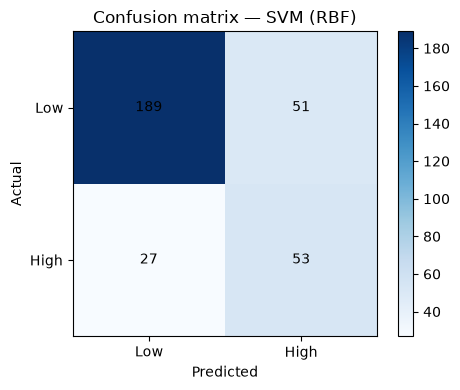

In [8]:
winner = results_df.iloc[0]["Model"]
pipe = best[winner]
pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

print(f"Winner: {winner}")
print(f"Test accuracy: {accuracy_score(y_test, pred):.4f}")
print(f"Test macro-F1: {f1_score(y_test, pred, average='macro'):.4f}")
print()
print(classification_report(y_test, pred, target_names=["Low", "High"]))

cm = confusion_matrix(y_test, pred)
print("Confusion matrix (rows=actual, cols=predicted):")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Low", "High"]); ax.set_yticklabels(["Low", "High"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix — {winner}")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()


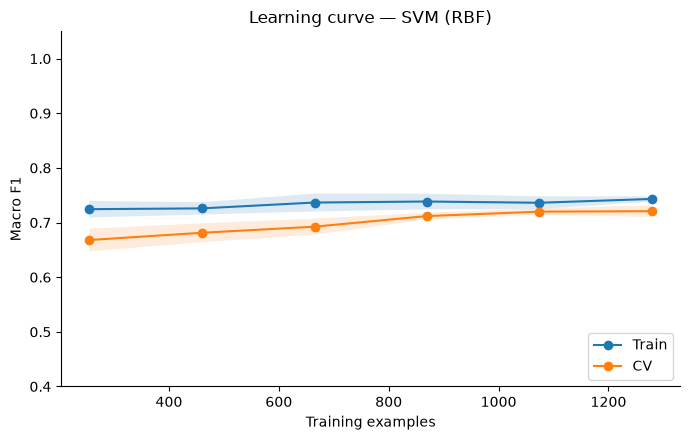

Final train=0.743, CV=0.721, gap=0.022


In [9]:
train_sizes, train_scores, val_scores = learning_curve(
    pipe, X, y, cv=skf, scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1, shuffle=True, random_state=SEED,
)
tr_m, tr_s = train_scores.mean(axis=1), train_scores.std(axis=1)
va_m, va_s = val_scores.mean(axis=1), val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.fill_between(train_sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15)
ax.fill_between(train_sizes, va_m - va_s, va_m + va_s, alpha=0.15)
ax.plot(train_sizes, tr_m, "o-", label="Train")
ax.plot(train_sizes, va_m, "o-", label="CV")
ax.set_xlabel("Training examples")
ax.set_ylabel("Macro F1")
ax.set_title(f"Learning curve — {winner}")
ax.set_ylim(0.4, 1.05)
ax.legend(loc="lower right")
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Final train={tr_m[-1]:.3f}, CV={va_m[-1]:.3f}, gap={tr_m[-1] - va_m[-1]:.3f}")


---
## Task 2.3 — Discussion of results

### 1. Performance ceiling
After EDA-aligned cleaning (ghost/dups, BP 0→NaN, Weight clip), BMI engineering, median imputation, SMOTE-in-CV, and fair tuning of seven models, macro-F1 sits around the **low–mid 0.70s**. Accuracy alone is close to the majority baseline (~75%); macro-F1 / High recall show the models learn the minority class. The ceiling is mostly **data**: Activity Index (strongest signal) is missing ~half the time.

### 2. Why tune every model?
Fixed defaults favour some algorithms and hurt others. RandomizedSearch on **each** model gives an equal opportunity before ranking — otherwise the “winner” can just be whoever had nicer default hyperparameters.

### 3. Winner and close rivals
We select by **CV macro-F1**. **SVM (RBF)** ranks first on that rule. Naive Bayes is close and can look slightly stronger on the single held-out test split — that is expected variance; we do **not** switch winners after peeking at the test set.

### 4. Overfitting vs generalisation
Baseline trees memorise (train F1 ≈ 1.0). After regularised search, train–test gaps for all seven stay within ~0.08. The winner’s learning curve shows train and CV approaching each other.

### 5. Class imbalance
SMOTE inside the pipeline (train folds only) improves High-class recall without leaking synthetics into validation. We did not stack `class_weight` on top.

### 6. Error analysis
High has lower precision than Low — some Low cases are flagged High. For a screening-style use case that may be acceptable; for certifying “High” fitness those false positives cost more. Threshold tuning would be a natural next step.

### 7. Limitations & next steps
1. Improve Activity Index collection (biggest bottleneck).  
2. Probability threshold / PR curve for business cost of errors.  
3. More representative sampling (current ~3:1 Low:High skew).

### GenAI note
AI helped draft pipeline structure, search loops, and learning-curve plotting. **Quality rules (BP→NaN, clips), feature choices, SMOTE-only decision, model list, CV selection rule, and interpretation of results are mine**, checked against the printed notebook outputs.
